# Assignment 1 — Antibody mass spectrum

> **AI-use disclosure:** OpenAI Codex assisted with writing and revising the code, calculations, figures, and explanations in this notebook. Automated checks support the calculations but do not replace scientific judgment or the author's review.

**Aim:** estimate the masses of five major antibody glycoforms, their mass variation across charge states, the average charge, and an effective radius.

**Reading guide:** Sections 1–3 inspect the data; Sections 4–8 perform the calculations; Section 9 collects the answers. Run the code cells from top to bottom. Throughout, abundance means **peak height**, and G1–G5 are labels ranked by intensity at 22+, not glycan-structure assignments.

## 1. Load and check the data

Read the two tab-separated columns in `group_1.txt`, skipping its eight header rows. The first column is mass-to-charge ratio (*m/z*); the second is intensity. Check that the data are numeric, finite, and ordered before analysis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from scipy.signal import find_peaks
from IPython.display import Markdown, display

proton_mass = 1.007276  # Da
plt.rcParams.update({"font.family": "Arial", "font.size": 11})

group_1 = pd.read_csv(
    "Assignment 1 Files/group_1.txt", sep="	", skiprows=8,
    names=["m/z", "Intensity"],
)
assert group_1.shape == (10347, 2), "Row count differs from the file header."
assert np.isfinite(group_1.to_numpy()).all(), "Non-numeric or missing values."
assert (group_1["Intensity"] >= 0).all(), "Negative intensities."
assert (np.diff(group_1["m/z"]) > 0).all(), "m/z must increase without duplicates."

# Shared formatting keeps the report consistent.
def show_table(frame, formats=None):
    labels = {
        "Abundance rank": "Glycoform",
        "Glycoform (22+ abundance rank)": "Glycoform",
        "Neutral mass (Da)": "Mass (Da)",
        "Weighted mean mass (Da)": "Weighted mean (Da)",
        "Weighted population SD (Da)": "Weighted SD (Da)",
    }
    formats = {labels.get(key, key): value for key, value in (formats or {}).items()}
    if "Glycoform" in frame.rename(columns=labels).columns:
        formats["Glycoform"] = "G{:d}"
    display(frame.rename(columns=labels).style.hide(axis="index").format(formats))


def plot_spectrum(limits):
    data = group_1.loc[group_1["m/z"].between(*limits)]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(data["m/z"], data["Intensity"], linewidth=1)
    ax.set(xlim=limits, ylim=(0, data["Intensity"].max() * 1.2))
    ax.set_xlabel("m/z", fontstyle="italic")
    ax.set_ylabel("Intensity")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    return fig, ax


print(f"Loaded {len(group_1):,} rows; no missing values or duplicate m/z values.")
show_table(group_1.head(), {"m/z": "{:,.3f}", "Intensity": "{:,.1f}"})

Loaded 10,347 rows; no missing values or duplicate m/z values.


m/z,Intensity
792.017,0.0
792.041,0.0
792.065,0.0
792.089,0.0
800.483,0.0


## 2. View the full spectrum

Plot intensity against *m/z* to locate the main antibody signal. All spectra use Arial, italic *m/z*, and commas for thousands.

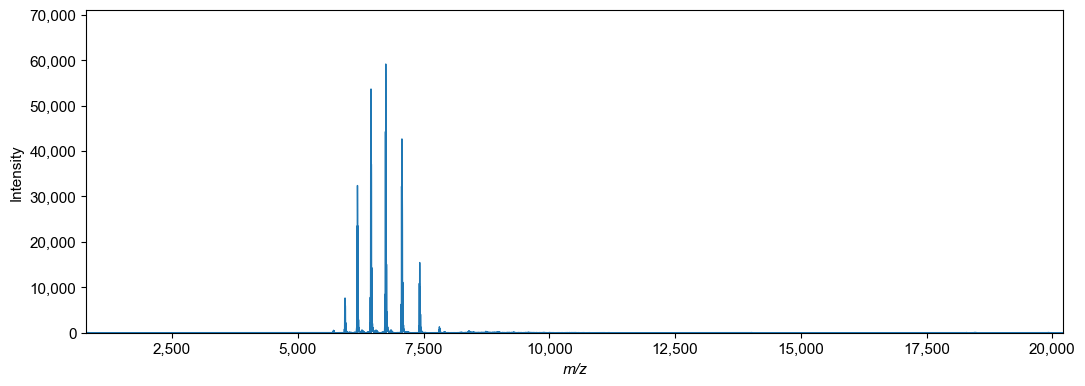

In [2]:
fig, ax = plot_spectrum((group_1["m/z"].min(), group_1["m/z"].max()))
fig.tight_layout()
plt.show()

## 3. Inspect the antibody region

Zoom to **5,500–8,000 m/z**. Six clusters have maximum intensities above 5,000; weaker clusters outside this selected series are excluded from the calculations below.

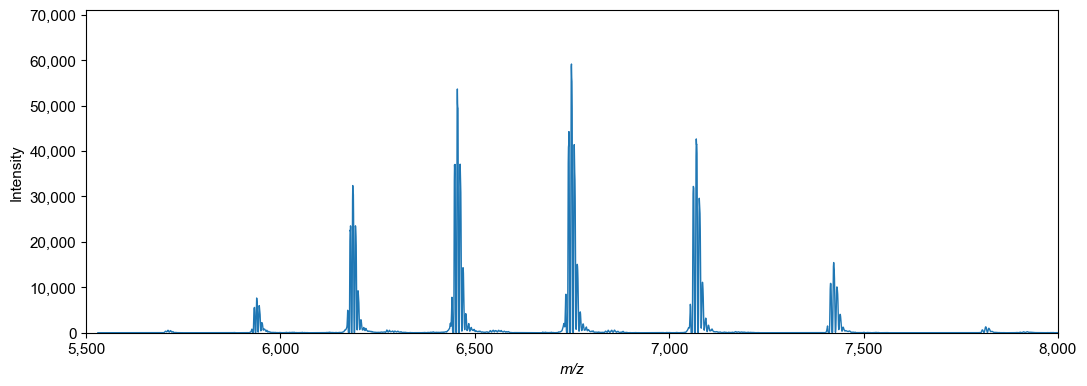

In [3]:
fig, ax = plot_spectrum((5500, 8000))
fig.tight_layout()
plt.show()

## 4. Assign charge states

Represent each of the six clusters by its strongest peak. A gap above 100 *m/z* between points exceeding 5,000 intensity separates these clusters.

For protonated ions, let $x=m/z$, $M$ be neutral mass, and $m_H=1.007276$ Da. Then $x=M/z+m_H$. For adjacent peaks $x_L<x_R$ from the same glycoform, with charges $z+1$ and $z$:

$$z=\frac{x_L-m_H}{x_R-x_L}, \qquad M=z(x-m_H).$$

Round the five independent charge estimates to integers and check that the assignments agree. The plot and table show the resulting **25+ to 20+** series. This assumes neighboring clusters differ by one proton and share the same dominant glycoform. [Method reference](https://help.waters.com/content/dam/waters/en/support/usermanuals/2003/6666387/auto_zabspec_api_issue4.pdf).

Unrounded charge estimates for the right-hand peaks: [24.018 22.983 21.983 21.014 19.997]


m/z,Intensity,Charge state,Mass (Da)
"5,938.691","7,641.2",25+,"148,442.09"
"6,185.909","32,396.1",24+,"148,437.65"
"6,455.012","53,645.7",23+,"148,442.10"
"6,748.606","59,139.0",22+,"148,447.17"
"7,069.710","42,652.3",21+,"148,442.75"
"7,423.207","15,448.5",20+,"148,443.99"


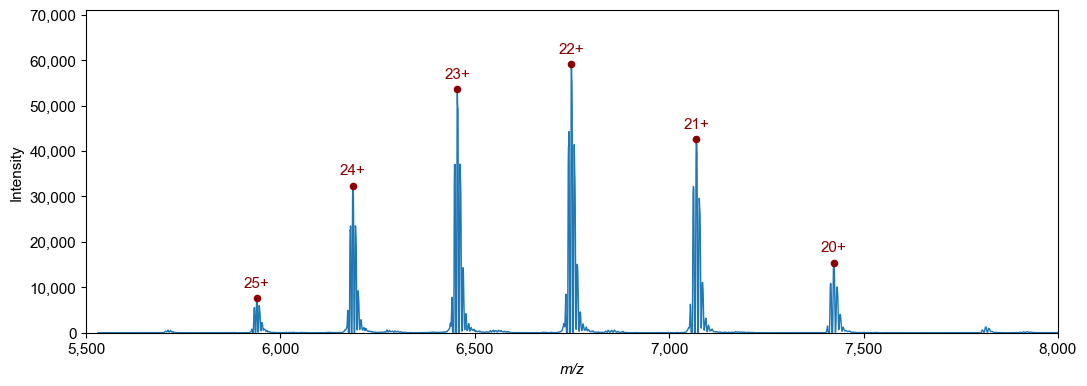

In [4]:
selected = group_1.loc[
    group_1["m/z"].between(5500, 8000) & (group_1["Intensity"] > 5000)
]
cluster_ids = selected["m/z"].diff().gt(100).cumsum()
charge_peaks = selected.loc[
    selected.groupby(cluster_ids)["Intensity"].idxmax()
].sort_values("m/z").reset_index(drop=True)
assert len(charge_peaks) == 6, "Expected six clusters."

# Each pair estimates the charge of the peak on its right.
peak_mz = charge_peaks["m/z"].to_numpy()
charge_estimates = (peak_mz[:-1] - proton_mass) / np.diff(peak_mz)
right_charges = np.rint(charge_estimates).astype(int)
assert np.all(np.abs(charge_estimates - right_charges) < 0.1)
assert np.all(np.diff(right_charges) == -1)
charges = np.r_[right_charges[0] + 1, right_charges]
assert charges.tolist() == [25, 24, 23, 22, 21, 20]
charge_peaks["Charge state"] = charges
charge_peaks["Neutral mass (Da)"] = charges * (peak_mz - proton_mass)

print("Unrounded charge estimates for the right-hand peaks:", charge_estimates.round(3))
show_table(charge_peaks, {
    "m/z": "{:,.3f}", "Intensity": "{:,.1f}",
    "Charge state": "{:d}+", "Neutral mass (Da)": "{:,.2f}",
})

fig, ax = plot_spectrum((5500, 8000))
for mz, intensity, charge in zip(peak_mz, charge_peaks["Intensity"], charges):
    ax.scatter(mz, intensity, color="darkred", s=20, zorder=3)
    ax.annotate(f"{charge}+", (mz, intensity), xytext=(0, 8),
                textcoords="offset points", ha="center", color="darkred")
fig.tight_layout()
plt.show()

## 5. Measure the five major glycoforms at 22+

Use SciPy’s `find_peaks` to detect local maxima, then select the five highest peaks within **6,700–6,800 m/z**. Label them **G1–G5 in decreasing intensity order** and calculate each intact antibody mass:

$$M=22(x-1.007276)\ \mathrm{Da}.$$

Relative height is normalized to the strongest peak (100%). These are masses at the measured peak maxima; they are not monoisotopic masses or identifications of specific glycans.

Glycoform,m/z,Intensity,Mass (Da),Relative height (%)
G1,"6,748.606","59,139.0","148,447.2",100.0
G2,"6,742.064","44,264.0","148,303.2",74.8
G3,"6,755.753","41,402.4","148,604.4",70.0
G4,"6,763.510","15,054.1","148,775.1",25.5
G5,"6,734.344","8,470.0","148,133.4",14.3


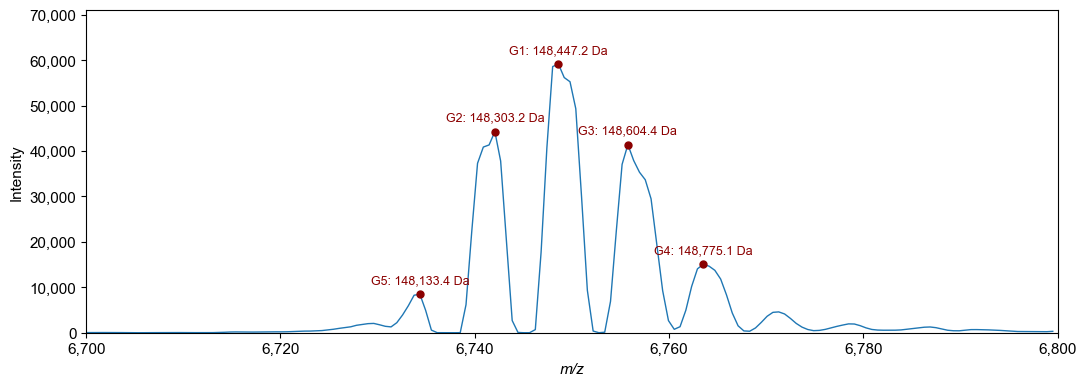

In [5]:
# Find local maxima with SciPy; reuse them when matching charge states.
peak_indices, _ = find_peaks(group_1["Intensity"].to_numpy())
local_maxima = group_1.iloc[peak_indices]
peaks_22 = local_maxima.loc[local_maxima["m/z"].between(6700, 6800)]
glycoforms_22 = peaks_22.nlargest(5, "Intensity").reset_index(drop=True)
assert len(glycoforms_22) == 5
assert np.all(np.diff(np.sort(glycoforms_22["m/z"])) > 2), "Peaks must be distinct."

glycoforms_22.insert(0, "Abundance rank", range(1, 6))
glycoforms_22["Neutral mass (Da)"] = 22 * (glycoforms_22["m/z"] - proton_mass)
glycoforms_22["Relative height (%)"] = (
    100 * glycoforms_22["Intensity"] / glycoforms_22["Intensity"].max()
)
show_table(glycoforms_22, {
    "m/z": "{:,.3f}", "Intensity": "{:,.1f}",
    "Neutral mass (Da)": "{:,.1f}", "Relative height (%)": "{:.1f}",
})

fig, ax = plot_spectrum((6700, 6800))
for _, peak in glycoforms_22.iterrows():
    ax.scatter(peak["m/z"], peak["Intensity"], color="darkred", s=25, zorder=3)
    label = f"G{int(peak['Abundance rank'])}: {peak['Neutral mass (Da)']:,.1f} Da"
    ax.annotate(label, (peak["m/z"], peak["Intensity"]), xytext=(0, 8),
                textcoords="offset points", ha="center", color="darkred", fontsize=9)
fig.tight_layout()
plt.show()

## 6. Combine mass estimates across 20+–25+

Match each G1–G5 peak across all six charge states using its 22+ mass as a reference. Select the strongest local maximum within **±60 Da** of that mass. The five matching windows do not overlap. Include matches below 5,000 intensity so weaker glycoforms are retained.

For each glycoform, weight its six masses $M_z$ by their corresponding peak intensities $I_z$:

$$\overline{M}_w=\frac{\sum_z I_zM_z}{\sum_z I_z}, \qquad
\sigma_w=\sqrt{\frac{\sum_z I_z(M_z-\overline{M}_w)^2}{\sum_z I_z}}.$$

Here $\sigma_w$ is the weighted **population standard deviation** across charge states, not a standard error or an uncertainty from repeated experiments. Calculations use unrounded masses. The supporting tables at the end show all 30 matches.

In [6]:
mass_tolerance = 60.0  # Da; select the highest maximum in each mass window
reference_masses = np.sort(glycoforms_22["Neutral mass (Da)"].to_numpy())
assert np.all(np.diff(reference_masses) > 2 * mass_tolerance)

matched_rows = []
for _, reference in glycoforms_22.iterrows():
    for charge in range(20, 26):
        candidate_masses = charge * (local_maxima["m/z"] - proton_mass)
        candidates = local_maxima.loc[
            (candidate_masses - reference["Neutral mass (Da)"]).abs() <= mass_tolerance
        ]
        if candidates.empty:
            raise ValueError(f"No peak found for glycoform {int(reference['Abundance rank'])} at {charge}+.")
        # Small fluctuations can produce multiple local maxima within one peak.
        peak = candidates.loc[candidates["Intensity"].idxmax()]
        matched_rows.append({
            "Glycoform (22+ abundance rank)": int(reference["Abundance rank"]),
            "Charge state": charge,
            "m/z": peak["m/z"],
            "Intensity": peak["Intensity"],
            "Neutral mass (Da)": charge * (peak["m/z"] - proton_mass),
        })

glycoform_charge_masses = pd.DataFrame(matched_rows)
summary_rows = []
for glycoform, measurements in glycoform_charge_masses.groupby("Glycoform (22+ abundance rank)"):
    assert measurements["Charge state"].tolist() == list(range(20, 26))
    masses = measurements["Neutral mass (Da)"].to_numpy()
    weights = measurements["Intensity"].to_numpy()
    assert np.all(np.isfinite(masses)) and np.all(np.isfinite(weights)) and np.all(weights > 0)
    mean_mass = np.average(masses, weights=weights)
    std_mass = np.sqrt(np.average((masses - mean_mass) ** 2, weights=weights))
    summary_rows.append({
        "Glycoform (22+ abundance rank)": glycoform,
        "Charge states used": len(measurements),
        "Weighted mean mass (Da)": mean_mass,
        "Weighted population SD (Da)": std_mass,
    })

glycoform_mass_summary = pd.DataFrame(summary_rows)
show_table(glycoform_mass_summary, {
    "Weighted mean mass (Da)": "{:,.2f}", "Weighted population SD (Da)": "{:.2f}",
})

Glycoform,Charge states used,Weighted mean (Da),Weighted SD (Da)
G1,6,"148,443.11",3.10
G2,6,"148,296.79",8.06
G3,6,"148,604.97",2.87
G4,6,"148,773.45",5.13
G5,6,"148,126.46",5.07


## 7. Calculate the average charge

At each charge state, sum the peak heights of G1–G5 to obtain $I_z$, then calculate:

$$\overline{z}=\frac{\sum_{z=20}^{25}zI_z}{\sum_{z=20}^{25}I_z}.$$

The overall result covers the five selected glycoforms at 20+–25+. The same formula gives a separate mean for each glycoform using only its own intensities. An average charge may be noninteger.

In [7]:
charge_distribution = (
    glycoform_charge_masses.groupby("Charge state", as_index=False)["Intensity"].sum()
    .rename(columns={"Intensity": "Summed peak intensity"})
)
assert charge_distribution["Charge state"].tolist() == list(range(20, 26))
charge_distribution["Signal fraction (%)"] = (
    100 * charge_distribution["Summed peak intensity"]
    / charge_distribution["Summed peak intensity"].sum()
)
average_charge_state = np.average(
    charge_distribution["Charge state"], weights=charge_distribution["Summed peak intensity"]
)
charge_summary_rows = []
for glycoform, peaks in glycoform_charge_masses.groupby("Glycoform (22+ abundance rank)"):
    charge_summary_rows.append({
        "Glycoform (22+ abundance rank)": glycoform,
        "Average charge state": np.average(peaks["Charge state"], weights=peaks["Intensity"]),
    })
glycoform_charge_summary = pd.DataFrame(charge_summary_rows)
assert 20 <= average_charge_state <= 25

show_table(charge_distribution, {
    "Charge state": "{:d}+", "Summed peak intensity": "{:,.1f}", "Signal fraction (%)": "{:.2f}",
})
show_table(glycoform_charge_summary, {"Average charge state": "{:.3f}"})
display(Markdown(f"**Overall average charge: {average_charge_state:.3f}+**"))

Charge state,Summed peak intensity,Signal fraction (%)
20+,"41,936.0",7.02
21+,"121,807.4",20.38
22+,"168,329.4",28.16
23+,"149,886.7",25.08
24+,"93,607.5",15.66
25+,"22,180.2",3.71


Glycoform,Average charge state
G1,22.322
G2,22.305
G3,22.354
G4,22.362
G5,22.364


**Overall average charge: 22.331+**

## 8. Estimate an effective antibody radius

**Assumption:** model the antibody as a sphere carrying the Rayleigh-limit charge of a water droplet of the same size.

$$ze=8\pi\sqrt{\epsilon_0\gamma R^3}
\quad\Longrightarrow\quad
R(\overline{z})=\left[\frac{(\overline{z}e)^2}{64\pi^2\epsilon_0\gamma}\right]^{1/3}.$$

Use $e=1.602176634\cdot10^{-19}$ C, $\epsilon_0=8.8541878188\cdot10^{-12}$ F/m, and water surface tension $\gamma=0.072$ N/m (approximately room temperature).

This estimates **radius from average charge**, not the average of individual radii. The spherical shape, water surface tension, and charging limit are model assumptions; charge alone does not establish the antibody's hydrodynamic radius or longest dimension. [Rayleigh equation](https://www.nature.com/articles/s42004-023-00818-4), [application to protein charging](https://doi.org/10.1016/S0003-2670(99)00601-7).

In [8]:
elementary_charge = 1.602176634e-19  # C
vacuum_permittivity = 8.8541878188e-12  # F/m
water_surface_tension = 0.072  # N/m; assumed room-temperature water

radius_from_average_charge_m = (
    (average_charge_state * elementary_charge) ** 2
    / (64 * np.pi ** 2 * vacuum_permittivity * water_surface_tension)
) ** (1 / 3)
radius_from_average_charge_nm = radius_from_average_charge_m * 1e9

# Substitute the radius back into the original Rayleigh equation.
reconstructed_charge = (
    8 * np.pi * np.sqrt(vacuum_permittivity * water_surface_tension
                       * radius_from_average_charge_m ** 3) / elementary_charge
)
assert np.isclose(reconstructed_charge, average_charge_state)
display(Markdown(
    f"**Effective radius: {radius_from_average_charge_nm:.2f} nm** "
    f"from an average charge of **{average_charge_state:.3f}+** "
    "(spherical water-droplet model at the Rayleigh limit)."
))

**Effective radius: 3.17 nm** from an average charge of **22.331+** (spherical water-droplet model at the Rayleigh limit).

## 9. Answers at a glance

The table below combines the **22+ peak mass** with the **intensity-weighted mean and population SD across 20+–25+** for each glycoform. G1–G5 retain their 22+ intensity ranking.

The overall charge uses all five selected glycoforms. The radius is an effective spherical estimate under the Rayleigh assumptions in Section 8. These results are generated from the calculations above so the summary stays consistent when the notebook is rerun.

In [9]:
summary_table = (
    glycoforms_22[["Abundance rank", "Neutral mass (Da)"]]
    .rename(columns={"Abundance rank": "Glycoform (22+ abundance rank)",
                     "Neutral mass (Da)": "Mass at 22+ (Da)"})
    .merge(glycoform_mass_summary, on="Glycoform (22+ abundance rank)", validate="one_to_one")
    .drop(columns="Charge states used")
)
show_table(summary_table, {
    "Mass at 22+ (Da)": "{:,.1f}",
    "Weighted mean mass (Da)": "{:,.2f}",
    "Weighted population SD (Da)": "{:.2f}",
})
display(Markdown(f"**Average charge:** {average_charge_state:.3f}+"))
display(Markdown(
    f"**Predicted effective radius:** {radius_from_average_charge_nm:.2f} nm "
    "(Rayleigh model; water surface tension 0.072 N/m)."
))

Glycoform,Mass at 22+ (Da),Weighted mean (Da),Weighted SD (Da)
G1,"148,447.2","148,443.11",3.10
G2,"148,303.2","148,296.79",8.06
G3,"148,604.4","148,604.97",2.87
G4,"148,775.1","148,773.45",5.13
G5,"148,133.4","148,126.46",5.07


**Average charge:** 22.331+

**Predicted effective radius:** 3.17 nm (Rayleigh model; water surface tension 0.072 N/m).

## Supporting checks and peak matches

Each column follows one glycoform across the six charge states. Masses are in Da; the second table gives the peak intensities used as weights.

The checks verify complete, unique peak matches; agreement with the 22+ reference peaks; stability for matching windows from ±30 to ±70 Da; and independent recalculation of the weighted mean and population SD. They check numerical consistency, not glycan identity or the physical validity of the radius model.

In [10]:
from math import fsum, sqrt

assert len(glycoform_charge_masses) == 30
assert not glycoform_charge_masses.duplicated(["Charge state", "m/z"]).any()
audit_differences = []
for _, reference in glycoforms_22.iterrows():
    glycoform = int(reference["Abundance rank"])
    matched = glycoform_charge_masses.loc[
        glycoform_charge_masses["Glycoform (22+ abundance rank)"] == glycoform
    ]
    assert matched["Charge state"].tolist() == list(range(20, 26))
    assert np.isclose(matched.loc[matched["Charge state"] == 22, "m/z"].iloc[0],
                      reference["m/z"], rtol=0, atol=1e-9)
    for _, peak in matched.iterrows():
        z = int(peak["Charge state"])
        mass_offsets = z * (local_maxima["m/z"] - proton_mass) - reference["Neutral mass (Da)"]
        for tolerance in (30, 40, 50, 60, 70):
            candidates = local_maxima.loc[mass_offsets.abs() <= tolerance]
            assert not candidates.empty
            best_mz = candidates.loc[candidates["Intensity"].idxmax(), "m/z"]
            assert best_mz == peak["m/z"], "Peak match depends on the matching window."

    # Independent scalar arithmetic checks the NumPy calculations.
    pairs = list(zip(matched["Neutral mass (Da)"], matched["Intensity"]))
    total_weight = fsum(weight for mass, weight in pairs)
    mean_check = fsum(mass * weight for mass, weight in pairs) / total_weight
    sd_check = sqrt(fsum(weight * (mass - mean_check) ** 2 for mass, weight in pairs) / total_weight)
    reported = glycoform_mass_summary.loc[
        glycoform_mass_summary["Glycoform (22+ abundance rank)"] == glycoform
    ].iloc[0]
    assert np.isclose(mean_check, reported["Weighted mean mass (Da)"], rtol=0, atol=1e-8)
    assert np.isclose(sd_check, reported["Weighted population SD (Da)"], rtol=0, atol=1e-8)
    audit_differences.extend((matched["Neutral mass (Da)"] - reference["Neutral mass (Da)"]).abs())

charge_check = fsum(
    row["Charge state"] * row["Intensity"] for _, row in glycoform_charge_masses.iterrows()
) / fsum(glycoform_charge_masses["Intensity"])
assert np.isclose(charge_check, average_charge_state, rtol=0, atol=1e-12)
assert np.isclose(charge_distribution["Signal fraction (%)"].sum(), 100)
assert len(summary_table) == 5

print("Checks passed: 30 unique matches; stable peak selection; weighted statistics agree.")
print(f"Largest mass difference from its 22+ reference: {max(audit_differences):.2f} Da.")
for quantity, precision in [("Neutral mass (Da)", 2), ("Intensity", 1)]:
    display(Markdown(f"**{quantity} by charge state**"))
    matrix = glycoform_charge_masses.pivot(
        index="Charge state", columns="Glycoform (22+ abundance rank)", values=quantity
    )
    matrix.columns = [f"G{int(g)}" for g in matrix.columns]
    matrix.columns.name = None
    show_table(matrix.reset_index(), {
        "Charge state": "{:d}+", **{column: f"{{:,.{precision}f}}" for column in matrix.columns},
    })

Checks passed: 30 unique matches; stable peak selection; weighted statistics agree.
Largest mass difference from its 22+ reference: 21.17 Da.


**Neutral mass (Da) by charge state**

Charge state,G1,G2,G3,G4,G5
20+,"148,443.99","148,293.05","148,608.91","148,774.10","148,128.65"
21+,"148,442.75","148,282.07","148,603.70","148,778.35","148,121.65"
22+,"148,447.17","148,303.24","148,604.42","148,775.05","148,133.42"
23+,"148,442.10","148,301.34","148,608.71","148,775.60","148,122.48"
24+,"148,437.65","148,299.85","148,600.74","148,764.10","148,124.76"
25+,"148,442.09","148,294.81","148,601.90","148,761.96","148,135.50"


**Intensity by charge state**

Charge state,G1,G2,G3,G4,G5
20+,"15,448.5","10,859.4","10,088.6","4,050.8","1,488.6"
21+,"42,652.3","32,200.9","29,595.0","11,105.4","6,253.8"
22+,"59,139.0","44,264.0","41,402.4","15,054.1","8,470.0"
23+,"53,645.7","37,043.2","37,083.4","14,315.5","7,798.9"
24+,"32,396.1","23,518.0","23,527.5","9,227.0","4,938.9"
25+,"7,641.2","5,557.2","5,964.1","2,225.4",792.2
